# Zeno-clock circuit feasibility on Nighthawk and Heron

This notebook estimates the hardware cost of running the superposed-schedule Zeno circuit from Seidel et al. (Fig. 1(b) of the paper) on IBM's two current processor families, Nighthawk and Heron. The goal is to decide whether the Fig. 1(b) sweep fits inside the free-tier monthly hardware budget, and if so which processor family would be most suitable.

Written by Claude and edited and checked by Sara Sussman and Olivia Seidel


## Background

### The quantum Zeno effect

The quantum Zeno effect occurs when you drive a quantum system continuously between its two levels. If left alone it oscillates from one to the other and back. If instead it is measured many times during the drive, each measurement collapses it back toward the starting state. Frequent measurement "freezes" the dynamics. The effect has been verified in superconducting qubits, trapped ions, cold atoms, and other platforms.

The survival probability $P_0^{(N)}$ as a function of the number of measurements is derived in Sec. 3 of Seidel et al. and plotted as the grey curve labeled "$\delta=0$ run" in Fig. 2(a).

In traditional Zeno experiments, the measurement times are programmed in advance into classical control electronics, which trigger each measurement at a specified laboratory time. They are typically parameters programmed into the apparatus, rather than quantum degrees of freedom.

### The experiment

Seidel et al. use a schedule qubit to place two measurement schedules, $\mathcal A$ and $\mathcal B$, in a coherent quantum superposition. The two schedules are drawn in Fig. 1(a) of the paper, and the full circuit is in Fig. 1(b).

Measuring the schedule qubit in the $\{|+\rangle,|-\rangle\}\$ basis probes the interference between the two coherent schedule branches.

Each schedule contains $N$ measurements separated by $\Delta t$. The two schedules differ by a fixed time offset $\delta$. In schedule $\mathcal{A}$, the measurements occur at $t_k=k\Delta t$; in schedule $\mathcal{B}$, they occur at $t_k=k\Delta t+\delta$, for $k=1,\ldots,N$. Both evolutions have total duration $T+\delta$, where $T=N\Delta t$. The additional drive interval of duration $\delta$ occurs after the last measurement in $\mathcal{A}$ and before the measurement train in $\mathcal{B}$, and is coherently controlled by the schedule qubit.

In the relational description outlined in the paper, $t$ here labels a reading of the quantum reference clock rather than an external classical time parameter. The intervals $\Delta t$ and $\delta$ are differences between these quantum clock readings. They determine the corresponding system rotations, $R_x(\Omega\Delta t)$ and $R_x(\Omega\delta)$.

### The qubits in the circuit

The circuit has three components, comprised of various qubits. There is a system qubit $S$, a schedule qubit $Q$, and a register of memory qubits $M_1,\ldots,M_N$, shown in Fig. 1(b).

The **system qubit** $S$ is the driven two-level system being studied. It plays the same role as a qubit being measured in a standard Zeno setup.

The **memory qubits** $M_1$ through $M_N$ record the $N$ measurements of $S$, with one memory per measurement:

1. Each memory starts in $|0\rangle$.
2. At the $k$-th measurement, a CNOT from $S$ to $M_k$ copies $S$'s computational-basis state into $M_k$. Since $M_k$ starts in $|0\rangle$, the CNOT correlates $|0\rangle_S$ with $|0\rangle_{M_k}$ and $|1\rangle_S$ with $|1\rangle_{M_k}$. If $S$ begins in a superposition of $|0\rangle$ and $|1\rangle$, this produces an entangled state. If we then look at $S$ by itself (ignoring $M_k$), $S$ is no longer in a quantum superposition, but rather in a classical probabilistic mixture of $|0\rangle$ and $|1\rangle$, which is the same reduced state that a projective measurement of $S$ would produce if its outcome were ignored.
3. The memories don't need to be read to get the system and schedule statistics. For the memory-parity test, we measure all memories in the $X$ basis at the end of the circuit.

The drive rotates $S$ between $|0\rangle$ and $|1\rangle$. Over the short interval $\Delta t$, the transition probability is $\sin^2(\Omega\Delta t/2)\approx(\Omega\Delta t/2)^2$. Each memory interaction removes the coherence between these states from the reduced state of $S$ (ignoring the memory qubits). In a standard Zeno experiment, increasing the number of recordings $N$ at fixed total drive time $T$ shortens the intervals $\Delta t=T/N$. As $N$ grows, the probability of finding $S$ in its initial state $|0\rangle$ at the end approaches one. This same sequence of drive rotations and memory interactions forms the common part of both measurement schedules in our circuit.

The **schedule qubit** $Q$ decides which schedule runs. It is prepared in $|+\rangle_Q = (|A\rangle_Q + |B\rangle_Q)/\sqrt{2}$ by the first Hadamard gate in the sequence, so both schedules run in superposition.

At $N=4$ (for example) the circuit runs as follows:

1. Prepare $Q$ in $(|A\rangle_Q + |B\rangle_Q)/\sqrt{2}$, $S$ in $|0\rangle$, and all four memories in $|0\rangle$.
2. Apply the schedule-$\mathcal{B}$ delay using a controlled rotation $CR_x(\Omega\delta)$ on $S$, thats controlled on $Q = |B\rangle_Q$. This performs the drive-only interval $\delta$ in the $\mathcal{B}$ branch.
3. Run the measurement train. Four times the sequence repeats where $S$ is driven for $\Delta t$ with $R_x(\Omega\Delta t)$, then a CNOT is done from $S$ into the next memory. These gates are not controlled by $Q$ and run identically in both branches.
4. Apply the schedule-$\mathcal{A}$ delay by doing $X \cdot CR_x(\Omega\delta) \cdot X$ on $Q$, which flips the control polarity so that the drive-only interval $\delta$ instead occurs in the $\mathcal{A}$ branch.
5. Apply a Hadamard on $Q$ to rotate the readout basis from $\{|A\rangle_Q, |B\rangle_Q\}$ to $\{|+\rangle_Q, |-\rangle_Q\}$, then measure $Q$ and $S$.

The outcome on $Q$ labels each shot as $|+\rangle_Q$ or $|-\rangle_Q$ and determines which of the conditional system statistics applies. The memories are either left unread or read in the $X$ basis, depending on which signature is being tested.

### Experiments to run on IBM devices

The proposed experiments test interference between two coherently controlled measurement schedules. The schedule qubit $Q$ controls which schedule is applied, and measuring it in the $|\pm\rangle_Q$ basis probes interference between the two branches. We consider two tests here, where one uses the conditional system probabilities and the other uses correlations between the memories.

**Experiment 1: How schedule interference changes the result.**

First, we run the ordinary Zeno sequence as a reference, with $\delta=0$, and measure how often $S$ ends in $|0\rangle$.

Then we run the circuit with the two schedules in superposition. We keep only the shots where the schedule qubit gives the $|-\rangle_Q$ outcome, and again measure how often $S$ ends in $|0\rangle$.

The paper predicts that these two probabilities add up to one. For example, if the reference gives a 90% chance of finding $S$ in $|0\rangle$, the minus-selected shots should give a 10% chance. Written mathematically,

$$
P_0^{(N,-)} = 1-P_0^{(N)}.
$$

Here, $P_0^{(N)}$ is the reference probability and $P_0^{(N,-)}$ is the minus-selected probability. This is gives us a precise prediction for the ideal circuit whenever the minus outcome can occur.

The test is to measure these two probabilities and check whether they follow this relation. We also repeat the experiment by randomly choosing one schedule on each run. This lets us compare using the same two schedules with and without interference, and check whether interference changes the measurement results.

**Experiment 2: Checking correlations between the memories.**

At the end of the circuit, we measure all the memory qubits in the $X$ basis, where each result is labelled $+1$ or $-1$. We keep only the shots where the schedule qubit gives the $|-\rangle_Q$ outcome.

The ideal circuit predicts a simple pattern: **an odd number of memories should give $-1$ in every retained shot.** The individual memory results can vary, but this pattern should always hold. Equivalently, multiplying all the memory results together should give $-1$. This is what “memory parity of $-1$” means.

For comparison, the ideal classical or dephased schedule circuit gives odd and even numbers of minus results equally often. This test therefore checks whether interference between the schedules produces the predicted pattern in the memory results.

Agreement with these predictions, together with comparison to classical or dephased schedule controls, would provide evidence for interference between the two measurement schedules. In the paper’s relational description, these schedules are defined relative to a quantum reference clock. These tests probe how coherence between the schedules affects the system probabilities and memory correlations.


## What this notebook computes

The target run is the point $N = 8$, $\Omega T = 3$, with $\Omega\delta$ swept across $[0, \pi]$. This matches Fig. 1(b) of the paper. The circuit uses $N + 2$ qubits: $S$, $Q$, and $N$ memories $M_1$ through $M_N$.

The gate sequence from Fig. 1(b) was described above for $N=4$; the same structure applies at $N=8$ with eight memories instead of four.

Nighthawk and Heron have different connectivity graphs. Nighthawk uses a square lattice, with four nearest neighbors for an interior qubit. Heron uses a heavy-hex lattice, with two or three nearest neighbors for most qubits. The system qubit $S$ must interact with $Q$ and with each memory in turn, and the connectivity determines how many of those partners $S$ can hold adjacent at once. On Nighthawk, $S$ can hold $Q$ plus three memories; on Heron, $Q$ plus two memories. Any remaining memory must be reached through SWAPs, each of which costs three CNOTs, because the SWAP gate factors as $\mathrm{SWAP}(a,b) = \mathrm{CNOT}(a,b)\cdot\mathrm{CNOT}(b,a)\cdot\mathrm{CNOT}(a,b)$, and three is the minimum possible CNOT count for a SWAP (Nielsen and Chuang, Fig. 1.7).

The notebook runs the feasibility analysis twice. Part A uses `optimization_level=0`, which does no gate-level optimization and gives a conservative upper bound on the hardware cost. Part B uses `optimization_level=2`, the standard choice for hardware submission, which uses SABRE routing and gate cancellation to produce a lower cost circuit. A dedicated section between the two parts explains why Part B's optimizations preserve the physics of the paper's analysis.


In [ ]:
# Install (uncomment first time on Colab)
!pip install qiskit pylatexenc matplotlib networkx --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00


In [ ]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.transpiler import CouplingMap
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec
import math
import networkx as nx

## Connectivity of Nighthawk and Heron

Nighthawk uses a square lattice: an interior qubit has four neighbors, an edge qubit three, a corner qubit two. Nighthawk r1 has 120 qubits and 218 couplers. Heron uses a heavy-hex lattice (hexagons with one extra qubit on each edge): most qubits have two neighbors, a smaller set has three, none has four. Heron r2 has 156 qubits and 176 couplers.

For the Zeno circuit, this connectivity difference turns into routing overhead. Every two-qubit gate in the circuit involves $S$. The number of qubits that can be kept adjacent to $S$ at the same time equals the degree of $S$'s physical location.

Example at $N=4$. The circuit uses six qubits: $S$, $Q$, $M_1$ to $M_4$. All five others must interact with $S$. On Nighthawk, $S$ sits at a degree-4 node and can hold three memories plus $Q$ adjacent. One memory requires a SWAP. On Heron, $S$ sits at a degree-3 node and can hold two memories plus $Q$ adjacent. Two memories require SWAPs. A SWAP costs three CNOTs, so Heron pays an extra three CNOTs per leftover memory. At $N=4$, Nighthawk has one leftover and Heron has two. The gap grows with $N$.

The cell below draws a small patch of each lattice, nodes colored by degree.


Square lattice avg degree: 3.00   Heavy-hex avg degree: 2.25


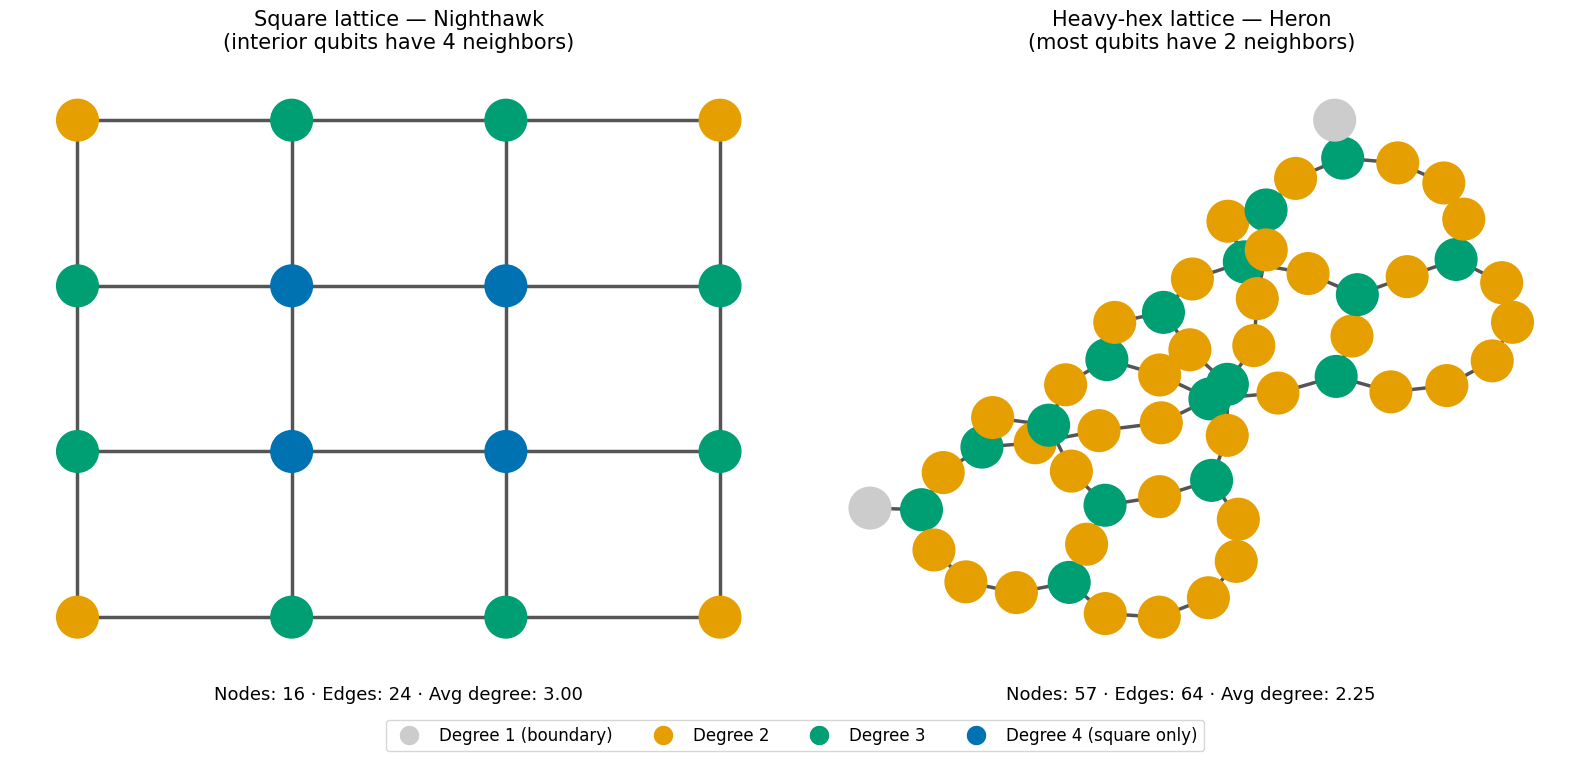

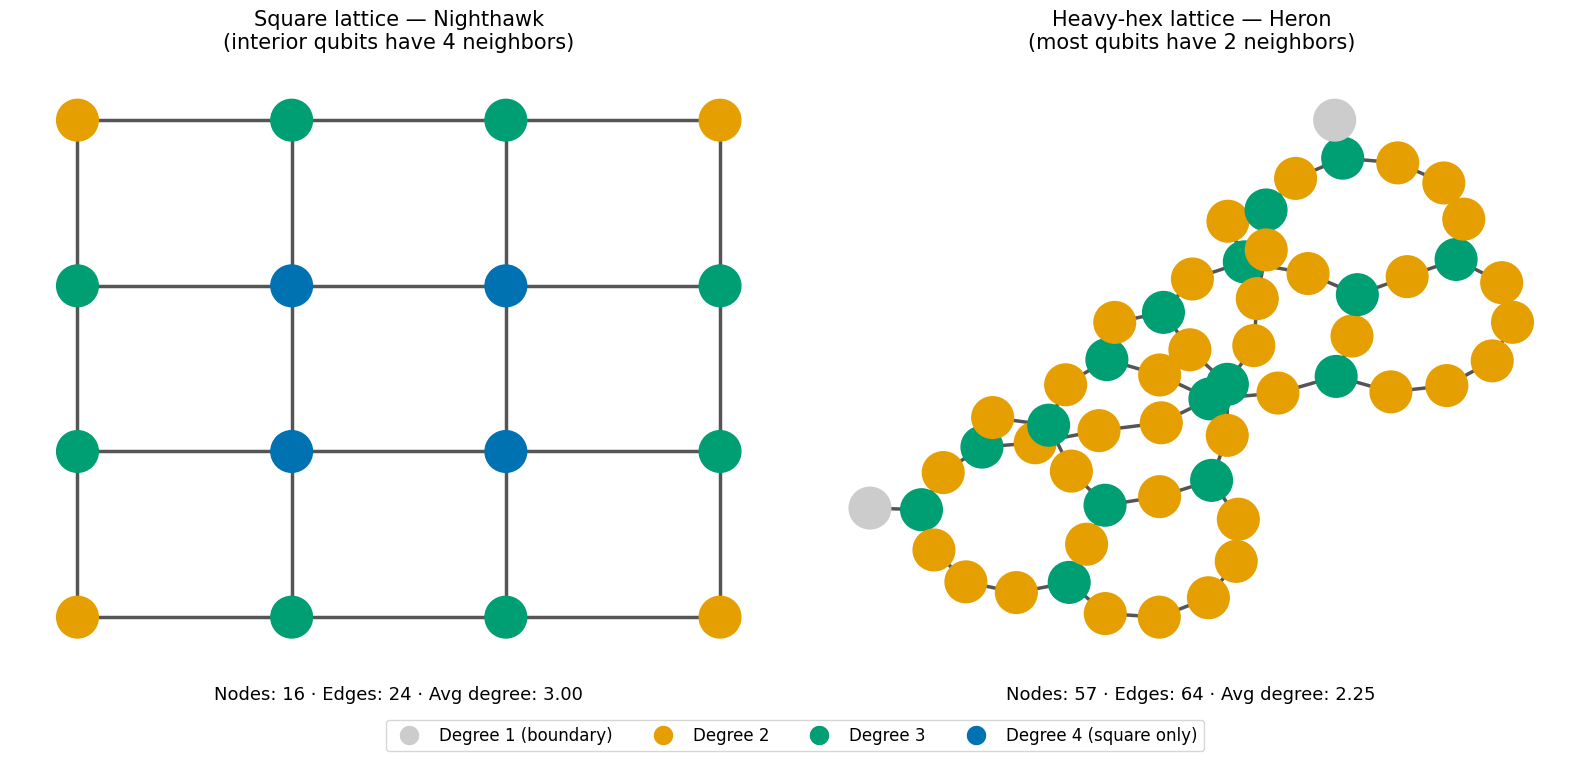

In [ ]:
sq = CouplingMap.from_grid(4, 4)
G_sq = nx.Graph(); G_sq.add_edges_from(sq.get_edges())
pos_sq = {r*4 + c: (c, -r) for r in range(4) for c in range(4)}

hh = CouplingMap.from_heavy_hex(5)
G_hh = nx.Graph(); G_hh.add_edges_from(hh.get_edges())
try:
    pos_hh = nx.nx_agraph.graphviz_layout(G_hh, prog='neato')
except Exception:
    pos_hh = nx.kamada_kawai_layout(G_hh)

palette = {1: '#CCCCCC', 2: '#E69F00', 3: '#009E73', 4: '#0072B2'}
deg_sq = dict(G_sq.degree()); deg_hh = dict(G_hh.degree())
col_sq = [palette[deg_sq[n]] for n in G_sq.nodes()]
col_hh = [palette[deg_hh[n]] for n in G_hh.nodes()]

fig_l, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5))
nx.draw(G_sq, pos_sq, ax=ax1, node_color=col_sq, node_size=900,
        edge_color='#555555', width=2.5, with_labels=False)
ax1.set_title('Square lattice — Nighthawk\n(interior qubits have 4 neighbors)',
              fontsize=15, pad=14)
avg_sq = sum(deg_sq.values())/len(deg_sq)
ax1.text(0.5, -0.05, f'Nodes: {len(G_sq)} · Edges: {len(G_sq.edges())} · Avg degree: {avg_sq:.2f}',
         transform=ax1.transAxes, ha='center', fontsize=13)

nx.draw(G_hh, pos_hh, ax=ax2, node_color=col_hh, node_size=900,
        edge_color='#555555', width=2.5, with_labels=False)
ax2.set_title('Heavy-hex lattice — Heron\n(most qubits have 2 neighbors)',
              fontsize=15, pad=14)
avg_hh = sum(deg_hh.values())/len(deg_hh)
ax2.text(0.5, -0.05, f'Nodes: {len(G_hh)} · Edges: {len(G_hh.edges())} · Avg degree: {avg_hh:.2f}',
         transform=ax2.transAxes, ha='center', fontsize=13)

legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[1], markersize=15, label='Degree 1 (boundary)'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[2], markersize=15, label='Degree 2'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[3], markersize=15, label='Degree 3'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[4], markersize=15, label='Degree 4 (square only)'),
]
fig_l.legend(handles=legend_elements, loc='lower center', ncol=4,
             bbox_to_anchor=(0.5, -0.02), fontsize=12, frameon=True)
plt.tight_layout(); plt.subplots_adjust(bottom=0.10)
fig_l.savefig('lattice_comparison.jpg', dpi=250, bbox_inches='tight', facecolor='white')
print(f'Square lattice avg degree: {avg_sq:.2f}   Heavy-hex avg degree: {avg_hh:.2f}')
fig_l

## Construction of the Zeno-clock circuit at N = 3

The function below builds the circuit from Fig. 1(b) of the paper. The gate sequence was walked through step by step in the Background. Here it is implemented in Qiskit as a reusable function, with $N = 3$ picked for the schematic drawing. The parameters $\Omega T = 3$ and $\Omega\delta = \pi/4$ are a representative point from the Fig. 1(b) sweep range.

*Note on notation.* The two $X$ gates on $Q$ around the second $CR_x$ implement the open control (hollow dot in the paper's Fig. 1(b)) via the identity $X_Q \cdot CR_x \cdot X_Q = \text{open-}CR_x$; same operation, Qiskit's drawing convention is just more explicit than the paper's. The hollow dot is important because it is what makes the two controlled rotations occur on *opposite* branches of $Q$ — one on $\ket{B}_Q$, the other on $\ket{A}_Q$ — so the extra $\delta$ interval occurs once in each schedule, before the measurement train in $\mathcal{B}$ and after it in $\mathcal{A}$. Without the opposite-polarity second control, both $\delta$ intervals would occur on the same branch and the two-schedule construction would not work.

In [ ]:
def build_zeno_clock(N, Omega_T=3.0, Omega_delta=math.pi/4):
    '''Build the superposed-schedule Zeno circuit (Fig. 1(b) of the paper).

    N          number of memory qubits (= number of recording interactions)
    Omega_T    normalized total drive interval (set to 3.0 to match Fig. 1(b))
    Omega_delta  schedule offset in units of 1/Omega (defaults to pi/4;
                 Fig. 1(b) sweeps this across [0, pi])
    '''
    Omega_dt = Omega_T / N
    S = QuantumRegister(1, name='S')
    Q = QuantumRegister(1, name='Q')
    M = QuantumRegister(N, name='M')
    cr = ClassicalRegister(N + 2, name='c')
    qc = QuantumCircuit(S, Q, M, cr)

    qc.h(Q[0])                                # prepare Q in |+>_Q
    qc.crx(Omega_delta, Q[0], S[0])           # schedule-B start delay

    for i in range(N):                        # measurement train
        qc.rx(Omega_dt, S[0])
        qc.cx(S[0], M[i])

    qc.x(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])           # schedule-A end delay (open ctl)
    qc.x(Q[0])

    qc.h(Q[0])                                # readout prep
    qc.measure(S[0], cr[0])
    qc.measure(Q[0], cr[1])
    for i in range(N):
        qc.measure(M[i], cr[2 + i])
    return qc

N_demo = 3
qc_demo = build_zeno_clock(N_demo)
print(f'Zeno-clock circuit (N={N_demo}): {qc_demo.num_qubits} qubits, abstract depth {qc_demo.depth()}')
print(f'Abstract gate counts (before transpile): {dict(qc_demo.count_ops())}')

Zeno-clock circuit (N=3): 5 qubits, abstract depth 12
Abstract gate counts (before transpile): {'measure': 5, 'rx': 3, 'cx': 3, 'h': 2, 'crx': 2, 'x': 2}


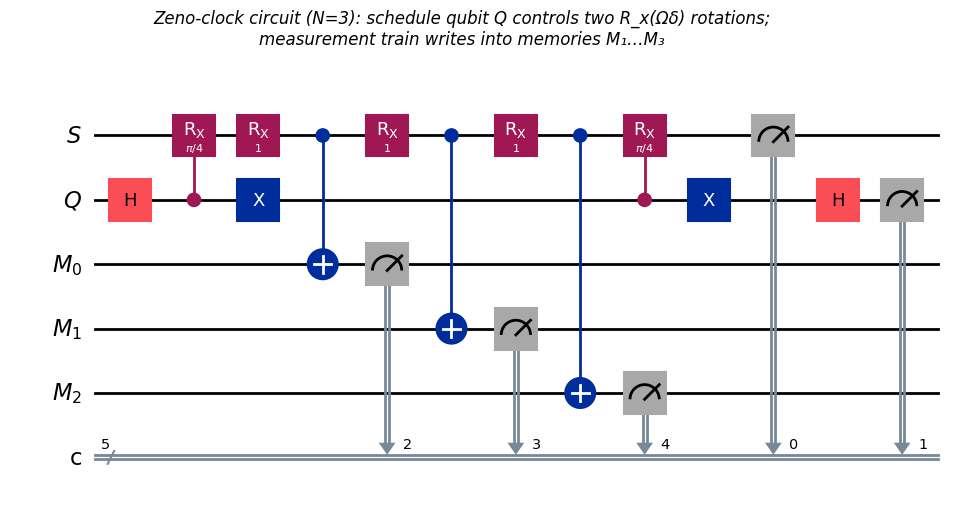

In [ ]:
fig_zeno = qc_demo.draw(output='mpl', style='iqp', fold=-1)
fig_zeno.suptitle(f'Zeno-clock circuit (N={N_demo}): schedule qubit Q controls two R_x(Ωδ) rotations;\n'
                  'measurement train writes into memories M₁…M₃',
                  fontsize=12, y=1.02, style='italic')
fig_zeno.savefig('zeno_panel_b.jpg', dpi=200, bbox_inches='tight', facecolor='white')
fig_zeno

## 2-qubit gate primitives on native connectivity

The circuit contains two kinds of two-qubit interaction: the controlled rotation $CR_x$ (appears twice) and the drive-and-record block, which is $R_x(\Omega\Delta t)$ on $S$ followed by a CNOT from $S$ to a fresh memory (appears $N$ times). Neither is a native gate on IBM hardware — the native 2-qubit basis is CNOT only — so each must be decomposed. The cell below transpiles each primitive on a bare 2-qubit coupling map to get its per-primitive CNOT count and depth.

Because these 2-qubit gate primitives run on just two qubits that are already adjacent, the CNOT count is stable at every optimization level, from 0 up. (The total gate count can differ — opt=1 and higher combine adjacent single-qubit rotations, opt=0 does not — but the CNOT count is a mathematical property of the decomposition and doesn't change.) The per-primitive CNOT counts are reliable building blocks for the rest of the analysis. In the next section we add them up to get an *ideal* cost — the cost the full circuit would have if every pair of interacting qubits could be placed adjacent on the chip. In Parts A and B we compare that ideal against the actual transpiled cost on Nighthawk and Heron. The gap tells us how much each chip's connectivity costs in routing SWAPs.

In [ ]:
basis = ['cx', 'rz', 'sx', 'x', 'measure']
cmap_pair = CouplingMap([[0, 1], [1, 0]])

# Primitive 1: controlled-R_x on a native 2-qubit pair
qc_cr = QuantumCircuit(2)
qc_cr.crx(math.pi/4, 0, 1)
tqc_cr = transpile(qc_cr, basis_gates=basis, coupling_map=cmap_pair,
                   optimization_level=1, seed_transpiler=42)
cr_cx    = tqc_cr.count_ops().get('cx', 0)
cr_depth = tqc_cr.depth(lambda g: len(g.qubits) == 2)
print(f'Controlled-R_x primitive: {cr_cx} CNOTs, 2q-depth {cr_depth}')

# Primitive 2: drive + record block (R_x on S, then CNOT S -> M)
qc_rec = QuantumCircuit(2)
qc_rec.rx(0.4, 0)
qc_rec.cx(0, 1)
tqc_rec = transpile(qc_rec, basis_gates=basis, coupling_map=cmap_pair,
                    optimization_level=1, seed_transpiler=42)
rec_cx    = tqc_rec.count_ops().get('cx', 0)
rec_depth = tqc_rec.depth(lambda g: len(g.qubits) == 2)
print(f'Drive + record primitive:   {rec_cx} CNOT,  2q-depth {rec_depth}')

fig_cr  = tqc_cr.draw(output='mpl', style='iqp', fold=-1)
fig_cr.savefig('zeno_panel_a.jpg', dpi=200, bbox_inches='tight', facecolor='white')
plt.close(fig_cr)
fig_rec = tqc_rec.draw(output='mpl', style='iqp', fold=-1)
fig_rec.savefig('zeno_panel_a2.jpg', dpi=200, bbox_inches='tight', facecolor='white')
plt.close(fig_rec)

Controlled-R_x primitive: 2 CNOTs, 2q-depth 2
Drive + record primitive:   1 CNOT,  2q-depth 1


## Block-wise ideal cost

If every pair of qubits that interacts could be placed adjacent on the chip, no routing SWAPs would be needed. The total ideal cost is just a sum over the gates in the circuit.

**CNOT count.** The circuit contains two kinds of two-qubit gate:

- $2$ controlled rotations ($CR_x$), one for the schedule-$\mathcal{B}$ delay and one for the schedule-$\mathcal{A}$ delay. From the atomic-primitives measurement above, each $CR_x$ costs $2$ CNOTs.
- $N$ drive-and-record pairs, one for each memory. From the atomic-primitives measurement above, each pair costs $1$ CNOT.

Adding these up: $2$ gates $\times\, 2$ CNOTs each from the schedule rotations, plus $N$ gates $\times\, 1$ CNOT each from the measurement train, gives a total of $2 \times 2 + N \times 1 = N + 4$ CNOTs.

**2-qubit depth.** Depth counts how many two-qubit gates have to happen in sequence (because they share a qubit) before the circuit is done. Normally, two gates that act on disjoint qubits can run at the same time, and the depth is less than the gate count. In this circuit, however, *every* two-qubit gate has $S$ as one of its endpoints: both $CR_x$ gates act on $(Q, S)$, and every drive-and-record pair acts on $(S, M_k)$. Since any two gates that share $S$ cannot run simultaneously, the two-qubit depth equals the two-qubit gate count: $N + 4$.

In short, the circuit is fully sequential on $S$, so the depth and the CNOT count are the same number: $N + 4$.

This is a lower bound. Any real coupling map with finite connectivity needs more CNOTs than this, because some memories cannot sit adjacent to $S$ at the same time. The gap between the ideal and the measured transpiled cost is the routing overhead. For example, at $N = 8$ the block-wise ideal is $12$ CNOTs, depth $12$. The actual transpiled cost at `opt=2` is $20$ CNOTs on Nighthawk (eight extra for routing five leftover memories) and $33$ CNOTs on Heron (twenty-one extra for routing six leftover memories, with fewer options for SABRE). We will explain what SABRE routing is below.

In [ ]:
Ns = [2, 4, 6, 8, 10, 12]
ideal_cx    = [N * rec_cx    + 2 * cr_cx    for N in Ns]
ideal_depth = [N * rec_depth + 2 * cr_depth for N in Ns]

print(f'{"N":>3} | {"CNOTs (ideal)":>14} | {"2q-depth (ideal)":>17}')
print('-' * 44)
for N, c, d in zip(Ns, ideal_cx, ideal_depth):
    print(f'{N:>3} | {c:>14} | {d:>17}')

  N |  CNOTs (ideal) |  2q-depth (ideal)
--------------------------------------------
  2 |              6 |                 6
  4 |              8 |                 8
  6 |             10 |                10
  8 |             12 |                12
 10 |             14 |                14
 12 |             16 |                16


## Helper functions for the two sweeps

Two helper functions are defined so that the two parts of the analysis use the same code path with different optimization levels.

The function `run_sweep(opt_level)` transpiles the Zeno circuit at every value of $N$ in the sweep onto both the Nighthawk-like and Heron-like coupling maps, and returns the resulting CNOT counts and 2-qubit depths. The function uses SABRE routing with eight random seeds and keeps the best result, which is apparently what IBM recommends for hardware submission. We will explain what SABRE routing is below.

The function `make_composite_figure(results, filename)` produces a four-panel composite figure from the results of a sweep. The four panels are: (a) the decomposition of the two atomic primitives on native connectivity; (b) the full Zeno-clock circuit at $N=3$; (c) 2-qubit depth versus $N$ for both topologies and the block-wise ideal; (d) CNOT count versus $N$ for both topologies and the block-wise ideal. Panel (c) also displays horizontal reference lines marking the depth at which cumulative 2-qubit gate error would bring total circuit fidelity to 0.8. The $0.8$ threshold is a rough rule of thumb: at that fidelity, the predicted signal is still visible with a few thousand shots per setting but has little margin to spare. Depths below the line are comfortable; depths at or above the line are the regime where error mitigation becomes necessary. The specific number is not important — $0.9$ would shift the lines down and $0.5$ would shift them up — $0.8$ is just a rough estimate for the place where it becomes harder to run the circuit without error mitigation.

### The 80%-fidelity threshold line in panel (c)

Panel (c) displays two horizontal reference lines, one per chip, marking the depth at which cumulative hardware errors would bring total circuit fidelity to $0.8$. The threshold depth $D_{80}$ is computed from a simple noise model that combines two effects.

The first effect is **accumulated 2-qubit gate error**. Each 2-qubit gate has fidelity $(1 - \varepsilon_{2q})$, where $\varepsilon_{2q}$ is the per-gate error rate. If the circuit applies $D$ 2-qubit gates in sequence and the errors multiply independently, the gate-error contribution to total fidelity is $(1 - \varepsilon_{2q})^D$.

The second effect is **$T_2$ dephasing over the circuit's wall-clock time**. Each 2-qubit gate takes a duration $t_{CZ}$, so a circuit of 2-qubit depth $D$ lasts about $D \cdot t_{CZ}$ in real time. During that time, each qubit dephases on the timescale $T_2$, which contributes a fidelity factor $\exp(-D \cdot t_{CZ} / T_2)$.

Combining the two, the total fidelity model is
$$F_{\text{total}}(D) \;\approx\; (1 - \varepsilon_{2q})^D \cdot \exp\!\left(-\frac{D \cdot t_{CZ}}{T_2}\right).$$
Setting $F_{\text{total}} = 0.8$ and solving for $D$ gives
$$D_{80} \;=\; \frac{\log(0.8)}{\log(1 - \varepsilon_{2q}) \;-\; t_{CZ}/T_2},$$
which is what the next cell implements. With representative hardware values from IBM public backend documentation, the threshold depths come out to $D_{80} \approx 41$ on Heron and $D_{80} \approx 67$ on Nighthawk. The gate-error term dominates in both cases; the $T_2$ term shifts both numbers down by about 10% compared with a gate-error-only estimate.

**What this threshold does and does not capture.** The two effects above dominate for shallow, fast circuits like this one. Three other noise channels are *not* included in the model: $T_1$ energy relaxation (which specifically biases $\ket{1}$ populations toward $\ket{0}$ and so would drag the inverted-branch result upward), readout error (typically 1–2% per qubit on current hardware), and crosstalk between simultaneous gates. For a quantitative experimental estimate, these would need to be added via `qiskit_aer` with a per-qubit noise model. The threshold line is a visual rule-of-thumb, not a replacement for such a simulation.



In [ ]:
def transpile_best(qc, cmap, basis, opt_level, trials=8):
    '''Transpile with several SABRE seeds; keep the lowest-CNOT result.
    At opt_level=0 SABRE isn't used (trivial layout + trivial routing),
    so trials > 1 is wasted but harmless.'''
    best = None
    for s in range(trials):
        tqc = transpile(qc, coupling_map=cmap, basis_gates=basis,
                        optimization_level=opt_level, seed_transpiler=s)
        cx = tqc.count_ops().get('cx', 0)
        if best is None or cx < best[0]:
            best = (cx, tqc)
    return best[1]


def run_sweep(opt_level, Ns=Ns, verbose=True):
    '''Transpile the Zeno circuit at every N on both topologies.'''
    cmap_nh = CouplingMap.from_grid(5, 5)
    cmap_hr = CouplingMap.from_heavy_hex(7)

    out = {'opt_level': opt_level, 'Ns': list(Ns),
           'nh_cx': [], 'nh_depth': [], 'hr_cx': [], 'hr_depth': []}
    for N in Ns:
        qc = build_zeno_clock(N)
        tqc_nh = transpile_best(qc, cmap_nh, basis, opt_level=opt_level)
        tqc_hr = transpile_best(qc, cmap_hr, basis, opt_level=opt_level)
        out['nh_cx'].append(tqc_nh.count_ops().get('cx', 0))
        out['nh_depth'].append(tqc_nh.depth(lambda g: len(g.qubits) == 2))
        out['hr_cx'].append(tqc_hr.count_ops().get('cx', 0))
        out['hr_depth'].append(tqc_hr.depth(lambda g: len(g.qubits) == 2))

    if verbose:
        print(f'Sweep at optimization_level = {opt_level}')
        print()
        print(f'{"N":>3} | {"ideal CNOTs":>12} | {"NH CNOTs":>10} | {"HR CNOTs":>10} || '
              f'{"ideal 2q-depth":>15} | {"NH 2q-depth":>12} | {"HR 2q-depth":>12}')
        print('-' * 100)
        for N, ic, nc, hc, id_, nd, hd in zip(out['Ns'], ideal_cx, out['nh_cx'], out['hr_cx'],
                                              ideal_depth, out['nh_depth'], out['hr_depth']):
            print(f'{N:>3} | {ic:>12} | {nc:>10} | {hc:>10} || {id_:>15} | {nd:>12} | {hd:>12}')
    return out


# Representative hardware values for the 80%-fidelity reference lines on panel (c).
# Median across qubits, from IBM public backend documentation. Daily calibration
# varies; this is a conservative round-number proxy, not a noise simulation.
HERON_T2_us      = 150; HERON_CZ_ns     = 68; HERON_CZ_err     = 5e-3
NIGHTHAWK_T2_us  = 200; NIGHTHAWK_CZ_ns = 68; NIGHTHAWK_CZ_err = 3e-3


def make_composite_figure(results, filename):
    """Build the 4-panel composite figure from a sweep's results."""
    opt_level = results['opt_level']
    Ns_       = results['Ns']
    nh_cx     = results['nh_cx']
    nh_depth  = results['nh_depth']
    hr_cx     = results['hr_cx']
    hr_depth  = results['hr_depth']

    img_cr   = mpimg.imread('zeno_panel_a.jpg')
    img_rec  = mpimg.imread('zeno_panel_a2.jpg')
    img_full = mpimg.imread('zeno_panel_b.jpg')

    color_nh = '#0072B2'; color_hr = '#E69F00'; color_id = '#666666'
    TITLE_FS = 19; SUBTITLE_FS = 14; LABEL_FS = 18; TICK_FS = 15; LEGEND_FS = 14

    # Combined fidelity model: F_total(D) ~ (1 - eps_2q)^D * exp(-D * t_CZ / T2)
    # Setting F_total = 0.8 and solving for D:
    #   D_80 = log(0.8) / [log(1 - eps_2q) - t_CZ / T2].
    # T2 is in microseconds, t_CZ in nanoseconds; convert so they match.
    heron_depth_80     = math.log(0.8) / (math.log(1 - HERON_CZ_err)
                                          - HERON_CZ_ns / (HERON_T2_us * 1000))
    nighthawk_depth_80 = math.log(0.8) / (math.log(1 - NIGHTHAWK_CZ_err)
                                          - NIGHTHAWK_CZ_ns / (NIGHTHAWK_T2_us * 1000))

    fig = plt.figure(figsize=(16, 13))
    gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1, 1.05],
                           height_ratios=[1, 1], wspace=0.22, hspace=0.32)

    # Top-left: two-qubit gate primitives.
    # Main title stays short so it does not bleed into panel (c).
    # Gate counts live as subtitles under each sub-image instead.
    ax_a_outer = fig.add_subplot(gs[0, 0]); ax_a_outer.axis('off')
    ax_a_outer.set_title('(a) Two-qubit gate primitives on native pair',
                         fontsize=TITLE_FS, loc='center', pad=8)
    gs_a = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[0, 0],
                                            height_ratios=[1, 1], hspace=0.45)
    ax_a1 = fig.add_subplot(gs_a[0]); ax_a1.imshow(img_cr); ax_a1.axis('off')
    ax_a1.set_title(f'Controlled-$R_x$: {cr_cx} CNOTs, 2q-depth {cr_depth}',
                    fontsize=SUBTITLE_FS, loc='center', pad=4)
    ax_a2 = fig.add_subplot(gs_a[1]); ax_a2.imshow(img_rec); ax_a2.axis('off')
    ax_a2.set_title(f'Drive + record: {rec_cx} CNOT, 2q-depth {rec_depth}',
                    fontsize=SUBTITLE_FS, loc='center', pad=4)

    # Bottom-left: full circuit at N=3
    ax_b = fig.add_subplot(gs[1, 0]); ax_b.imshow(img_full); ax_b.axis('off')
    ax_b.set_title(f'(b) Full Zeno-clock circuit (N={N_demo}):\n'
                   f'2 controlled-$R_x$ boxes + {N_demo} drive+record pairs',
                   fontsize=TITLE_FS, loc='center', pad=10)

    gs_r = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[:, 1],
                                            height_ratios=[1, 1], hspace=0.32)

    # Panel (c): depth vs N
    ax_c = fig.add_subplot(gs_r[0])
    ax_c.plot(Ns_, nh_depth,   'o-',  color=color_nh, linewidth=3.5, markersize=14, label='Nighthawk (square lattice)')
    ax_c.plot(Ns_, hr_depth,   's--', color=color_hr, linewidth=3.5, markersize=14, label='Heron (heavy-hex)')
    ax_c.plot(Ns_, ideal_depth,'^:',  color=color_id, linewidth=2.5, markersize=12, label='Block-wise ideal (no routing)')
    ax_c.axhline(nighthawk_depth_80, color=color_nh, linestyle=(0, (1, 1)), linewidth=2, alpha=0.6,
                 label=f'Nighthawk 80% fidelity limit (depth ≈ {nighthawk_depth_80:.0f};\n'
                       f'  T₂={NIGHTHAWK_T2_us}μs, t_CZ={NIGHTHAWK_CZ_ns}ns, ε_2q={NIGHTHAWK_CZ_err*100:.1f}%)')
    ax_c.axhline(heron_depth_80, color=color_hr, linestyle=(0, (1, 1)), linewidth=2, alpha=0.6,
                 label=f'Heron 80% fidelity limit (depth ≈ {heron_depth_80:.0f};\n'
                       f'  T₂={HERON_T2_us}μs, t_CZ={HERON_CZ_ns}ns, ε_2q={HERON_CZ_err*100:.1f}%)')
    ax_c.set_xlabel('N (memory qubits)', fontsize=LABEL_FS, labelpad=8)
    ax_c.set_ylabel('2-qubit gate depth', fontsize=LABEL_FS, labelpad=8)
    ax_c.set_title(f'(c) 2-qubit depth vs N  [opt={opt_level}]', fontsize=TITLE_FS, pad=12)
    ax_c.tick_params(axis='both', labelsize=TICK_FS)
    ax_c.legend(fontsize=LEGEND_FS - 3, loc='upper left', frameon=True)
    ax_c.grid(True, alpha=0.3); ax_c.set_xticks(Ns_)
    ax_c.set_ylim(0, max(max(hr_depth), heron_depth_80, nighthawk_depth_80) * 1.1)

    # Panel (d): CNOT count vs N
    ax_d = fig.add_subplot(gs_r[1])
    ax_d.plot(Ns_, nh_cx,   'o-',  color=color_nh, linewidth=3.5, markersize=14, label='Nighthawk (square lattice)')
    ax_d.plot(Ns_, hr_cx,   's--', color=color_hr, linewidth=3.5, markersize=14, label='Heron (heavy-hex)')
    ax_d.plot(Ns_, ideal_cx,'^:',  color=color_id, linewidth=2.5, markersize=12, label='Block-wise ideal (no routing)')
    ax_d.set_xlabel('N (memory qubits)', fontsize=LABEL_FS, labelpad=8)
    ax_d.set_ylabel('CNOT count', fontsize=LABEL_FS, labelpad=8)
    ax_d.set_title(f'(d) CNOT count vs N  [opt={opt_level}]', fontsize=TITLE_FS, pad=12)
    ax_d.tick_params(axis='both', labelsize=TICK_FS)
    ax_d.legend(fontsize=LEGEND_FS, loc='upper left', frameon=True)
    ax_d.grid(True, alpha=0.3); ax_d.set_xticks(Ns_)

    fig.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'Saved {filename} at 300 DPI')
    return fig


---

# Part A. Experiment 1 feasibility at optimization_level=0

The first pass uses `optimization_level=0`. The transpiler maps every gate to the native basis and inserts SWAPs where the coupling graph requires them, but does not reduce SWAPs through layout choice or combine adjacent gates. Each schematic box in the input corresponds to a visible sub-sequence in the output.

Because `opt=0` uses a trivial layout (logical qubit $k$ to physical qubit $k$) regardless of the coupling graph, it inserts more SWAPs than a competent layout would need. The resulting cost estimate is a conservative upper bound. Part B measures how much lower a competent submission would be. The physics executed by both is identical.

In [ ]:
results_opt0 = run_sweep(opt_level=0)

Sweep at optimization_level = 0

  N |  ideal CNOTs |   NH CNOTs |   HR CNOTs ||  ideal 2q-depth |  NH 2q-depth |  HR 2q-depth
----------------------------------------------------------------------------------------------------
  2 |            6 |         12 |         27 ||               6 |           12 |           24
  4 |            8 |         23 |         53 ||               8 |           19 |           41
  6 |           10 |         28 |         91 ||              10 |           25 |           49
  8 |           12 |         39 |        105 ||              12 |           30 |           72
 10 |           14 |         47 |        128 ||              14 |           40 |           95
 12 |           16 |         55 |        157 ||              16 |           48 |           99


### Composite figure at opt=0

Saved zeno_feasibility_opt0.jpg at 300 DPI


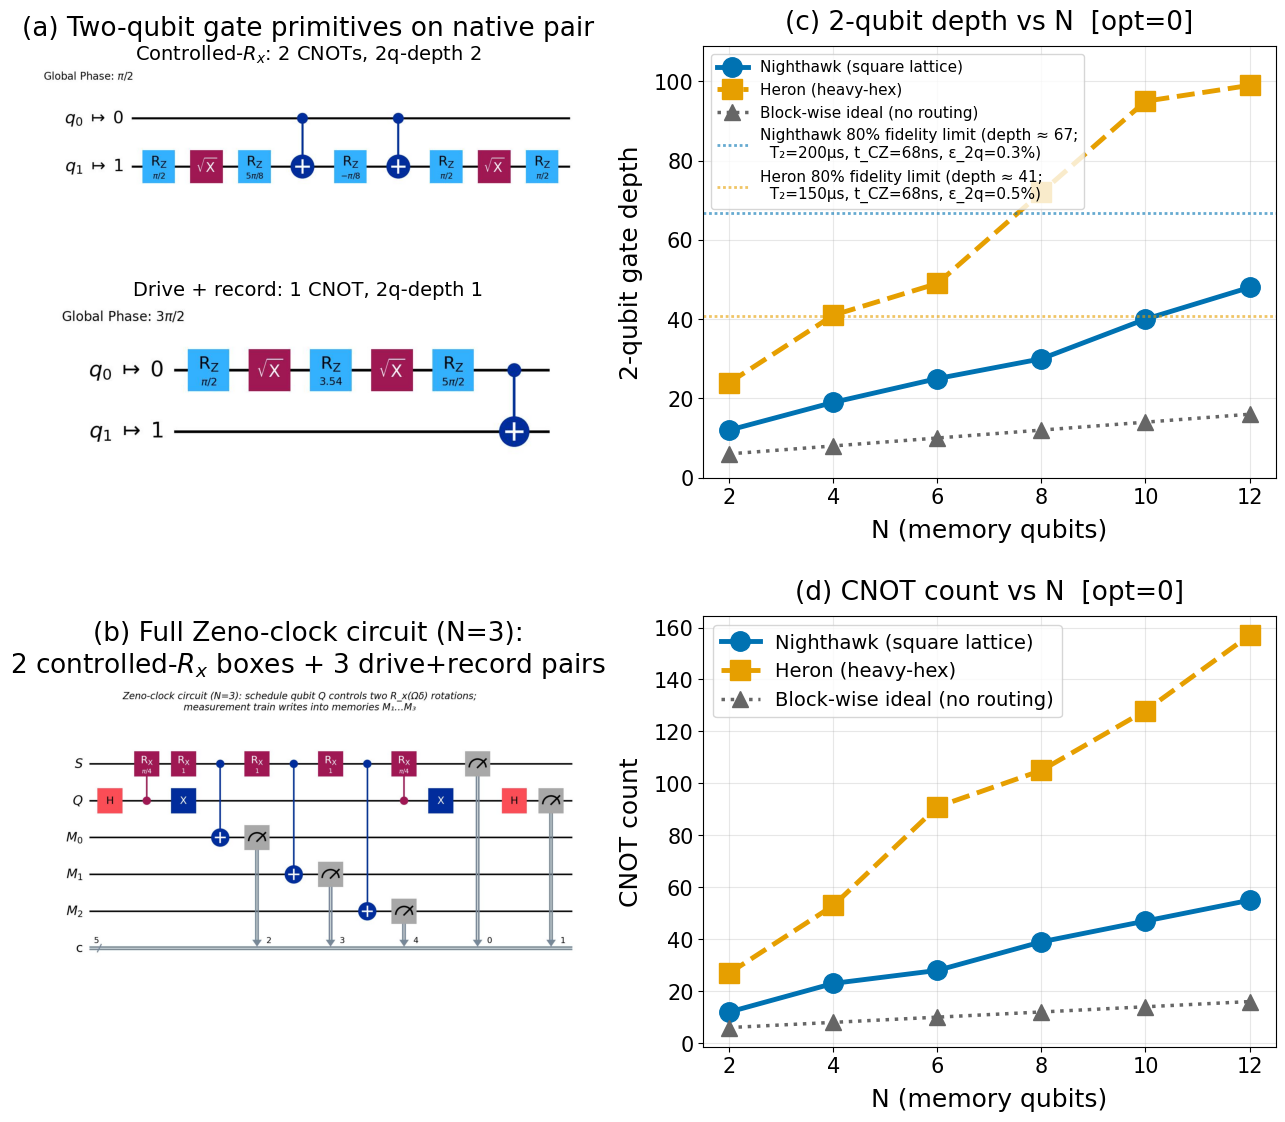

In [ ]:
fig_opt0 = make_composite_figure(results_opt0, filename='zeno_feasibility_opt0.jpg')

### Observations at opt=0

At $N=8$: Nighthawk needs $39$ CNOTs, depth $30$. Heron needs $105$ CNOTs, depth $72$.

Nighthawk sits well below both 80%-fidelity reference lines on panel (c), so gate error alone does not threaten the signal.

Heron's depth sits above the Heron reference line ($45$) for $N \ge 4$. In this regime, accumulated gate error alone would push circuit fidelity below $0.8$ before any decoherence is counted. At `opt=0`, Heron is marginal for the Fig. 1(b) sweep beyond the smallest values of $N$.

The Heron-to-Nighthawk ratio is about $3\times$ in CNOTs at $N=8$.

---

# Why optimization_level=2 preserves the physics

Before using a higher optimization level, this section explains why doing so cannot change the physical content of the circuit. The argument has two parts.

### The optimization level and what it controls

Qiskit's `transpile` function turns the abstract circuit into an equivalent circuit that respects the chip's native gate set (CNOT, $\sqrt X$, $X$, $R_z$, measurement) and its coupling map. The `optimization_level` parameter controls how aggressively the transpiler reduces the number of gates in the output. The levels are documented in the Qiskit transpiler guide ([docs.quantum.ibm.com/guides/set-optimization](https://docs.quantum.ibm.com/guides/set-optimization)).

| Level | Behavior |
|-------|----------|
| 0 | No optimization. Trivial layout, naive routing. Correct but gate-heavy. |
| 1 | Light optimization. SABRE routing, peephole cancellation. |
| 2 | Medium optimization. SABRE for layout and routing. Standard for hardware submission. |
| 3 | Heavy optimization. Full 2-qubit block resynthesis. Slower compile. |

### Two invariants the transpiler must respect

Every optimization level is required to preserve two properties of the circuit:

1. **Unitary preservation.** Every pass is required, as a hard invariant checked by the pass manager, to produce an output whose unitary equals the input's. The output of `opt=0` and `opt=2` compute the same unitary on the same logical qubits, and therefore produce the same measurement statistics — the same $p_\pm$, the same $P_0^{(N,\pm)}$, the same memory parity, the same complement relation.

2. **DAG preservation.** The transpiler respects the circuit's dependency graph. If gate $A$ shares a qubit with a later gate $B$, then $B$ cannot be moved before $A$. For the Zeno circuit, this means the recording CNOTs stay in order because they share $S$ with the drive rotations between them.

### Consequences for this specific circuit

Three things cannot change at any optimization level:

- **The number of recording CNOTs stays exactly $N$.** Each memory $M_k$ is a fresh qubit touched only by its one CNOT and its final measurement. Deleting the CNOT would change $M_k$'s measurement statistics, violating unitary preservation.
- **The order of the recording CNOTs is preserved.** All recording CNOTs share $S$, so DAG preservation forbids reordering.
- **The dephasing per recording is preserved.** However the CNOT is decomposed into native gates, the composite operation still equals a CNOT and still fully correlates $S$ with a fresh $\ket{0}_M$, which is the dephasing channel the paper assumes.

The transpiler can decompose non-native gates like $CR_x$, combine adjacent single-qubit rotations, insert SWAPs, and choose which physical qubits to use. None of these changes the unitary or the DAG. The physics is preserved; only the gate count and depth change.

### SABRE routing

SABRE (SWAP-based BidiREctional heuristic search) is the algorithm Qiskit uses at `opt_level=1,2,3` to decide where to insert SWAPs. It is described in Li, Ding, and Xie, ASPLOS 2019 ([arXiv:1809.02573](https://arxiv.org/abs/1809.02573)). SABRE only inserts SWAPs; it does not delete or reorder gates, so it respects both invariants above.

SABRE uses randomized tie-breaking, so different `seed_transpiler` values can produce different CNOT counts. Part B uses the best result from eight seeds, which is the standard discipline before hardware submission.

### Empirical comparison across all four optimization levels

The cell below transpiles the Zeno circuit at $N=8$ on the Nighthawk topology at every optimization level from 0 to 3, and reports the resulting CNOT count, 2-qubit depth, and total gate count. All four levels compute the same unitary and produce the same measurement statistics, as established above. Only the gate sequence differs.

In [ ]:
cmap_nh_cmp = CouplingMap.from_grid(5, 5)
N_cmp = 8
qc_cmp = build_zeno_clock(N_cmp)

print(f'Zeno circuit at N={N_cmp} on Nighthawk topology — best of 8 SABRE seeds per level:')
print(f'{"opt level":>10} | {"CNOTs":>6} | {"2q-depth":>8} | {"total gates":>12}')
print('-' * 48)
for opt in [0, 1, 2, 3]:
    tqc = transpile_best(qc_cmp, cmap_nh_cmp, basis, opt_level=opt)
    cx = tqc.count_ops().get('cx', 0)
    d2 = tqc.depth(lambda g: len(g.qubits) == 2)
    total = sum(tqc.count_ops().values())
    print(f'{opt:>10} | {cx:>6} | {d2:>8} | {total:>12}')

Zeno circuit at N=8 on Nighthawk topology — best of 8 SABRE seeds per level:
 opt level |  CNOTs | 2q-depth |  total gates
------------------------------------------------
         0 |     39 |       30 |          113
         1 |     21 |       21 |           87
         2 |     20 |       20 |           90
         3 |     18 |       18 |           76


---

# Part B. Experiment 1 feasibility at optimization_level=2

The second pass repeats the sweep at `optimization_level=2`. The physics executed is identical to Part A (by the argument above). The cost estimate is lower because SABRE picks a layout and SWAP placement that avoid the unnecessary SWAPs of trivial routing, and peephole cancellation combines adjacent single-qubit rotations. This is the cost estimate that would be submitted to hardware in practice.

In [ ]:
results_opt2 = run_sweep(opt_level=2)

Sweep at optimization_level = 2

  N |  ideal CNOTs |   NH CNOTs |   HR CNOTs ||  ideal 2q-depth |  NH 2q-depth |  HR 2q-depth
----------------------------------------------------------------------------------------------------
  2 |            6 |          6 |          6 ||               6 |            6 |            6
  4 |            8 |         11 |         14 ||               8 |           11 |           14
  6 |           10 |         14 |         20 ||              10 |           14 |           19
  8 |           12 |         20 |         33 ||              12 |           20 |           32
 10 |           14 |         22 |         41 ||              14 |           22 |           37
 12 |           16 |         31 |         53 ||              16 |           31 |           47


### Composite figure at opt=2

Saved zeno_feasibility_opt2.jpg at 300 DPI


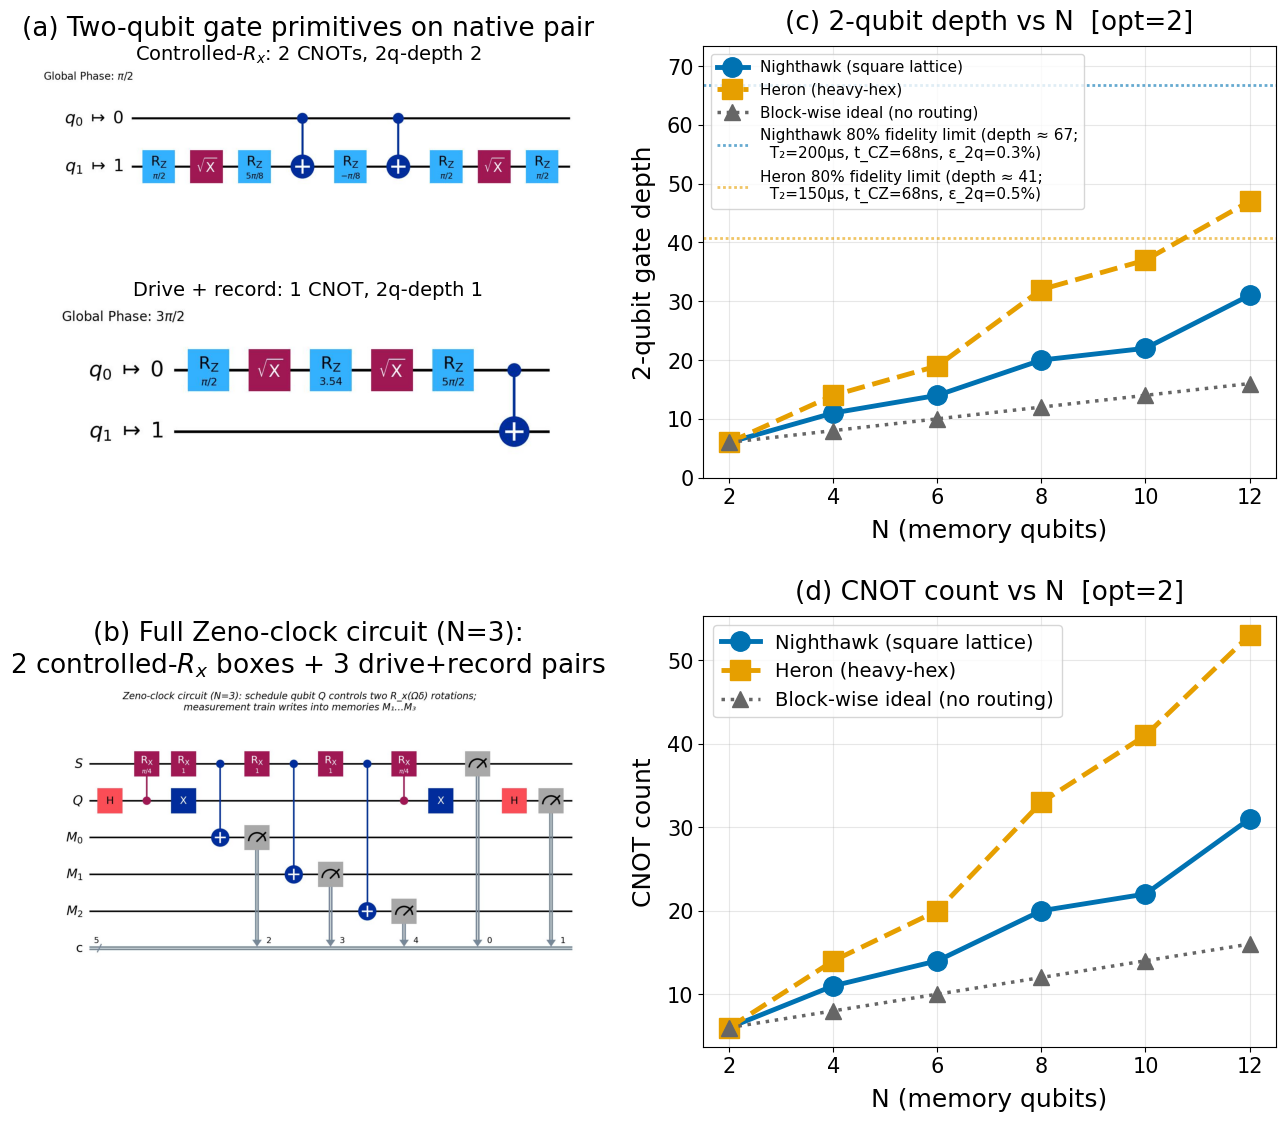

In [ ]:
fig_opt2 = make_composite_figure(results_opt2, filename='zeno_feasibility_opt2.jpg')

### Observations at opt=2

At $N=8$: Nighthawk needs $20$ CNOTs, depth $20$. Heron needs $33$ CNOTs, depth $32$.

Nighthawk sits well below both 80%-fidelity reference lines. Heron sits below its reference line through $N=10$ and just touches it at $N=12$ ($47$ vs. $45$). Both chips are feasible for the Fig. 1(b) sweep. Nighthawk has more headroom for larger $N$, which matters for the Fig. 1(a) sweep.

The table below compares the two parts at $N=8$. The physics is identical; only the gate count differs.

| metric | opt=0 Nighthawk | opt=2 Nighthawk | opt=0 Heron | opt=2 Heron |
|---|---:|---:|---:|---:|
| CNOTs | 39 | 20 | 105 | 33 |
| 2q-depth | 30 | 20 | 72 | 32 |

The `opt=0`-to-`opt=2` ratio is $2.0\times$ on Nighthawk and $3.2\times$ on Heron. The ratio is larger on Heron because its lower connectivity gives SABRE more opportunities to improve on `opt=0`'s trivial layout.

## Routing overhead relative to the block-wise ideal

The table below decomposes the `opt=2` cost at each $N$ into the block-wise ideal (the lower bound established above) and the routing overhead introduced by each topology.

In [ ]:
print(f'{"N":>3} | {"ideal CNOTs":>12} | {"NH CNOTs":>10} | {"HR CNOTs":>10} | {"NH overhead":>14} | {"HR overhead":>14}')
print('-' * 85)
for N, ic, nc, hc in zip(Ns, ideal_cx, results_opt2['nh_cx'], results_opt2['hr_cx']):
    nh_over = f'{nc - ic:+d} ({100*(nc-ic)/ic:+.0f}%)'
    hr_over = f'{hc - ic:+d} ({100*(hc-ic)/ic:+.0f}%)'
    print(f'{N:>3} | {ic:>12} | {nc:>10} | {hc:>10} | {nh_over:>14} | {hr_over:>14}')

  N |  ideal CNOTs |   NH CNOTs |   HR CNOTs |    NH overhead |    HR overhead
-------------------------------------------------------------------------------------
  2 |            6 |          6 |          6 |       +0 (+0%) |       +0 (+0%)
  4 |            8 |         11 |         14 |      +3 (+38%) |      +6 (+75%)
  6 |           10 |         14 |         20 |      +4 (+40%) |    +10 (+100%)
  8 |           12 |         20 |         33 |      +8 (+67%) |    +21 (+175%)
 10 |           14 |         22 |         41 |      +8 (+57%) |    +27 (+193%)
 12 |           16 |         31 |         53 |     +15 (+94%) |    +37 (+231%)


---

# Experiment 2: $X$-basis parity signature on the memory register

The second testable prediction is signature (4) of the paper: conditional on the $\ket{-}_Q$ outcome, the memory register is left in an eigenstate of its joint $X$-basis parity $\hat{\Sigma}_M = \prod_{k=1}^{N} \hat{X}_{M_k}$ with eigenvalue exactly $-1$, for every $N$, every spacing, and every $\delta$ with nonzero $\ket{-}_Q$ probability.

The circuit for this test differs from Experiment 1 by **one line only** — a layer of Hadamards on the memory qubits before the final measurement, rotating the $X$-basis parity into a $Z$-basis parity that the hardware can read directly. The controlled-$R_x$ boxes, the drive-and-record train, the $Q$ interferometer, and the $S$ and $Q$ readouts are unchanged. The two-qubit gate skeleton is identical, so the two-qubit depth and CNOT counts should match Experiment 1 within single-qubit-gate noise.

What changes is not the depth. It is the readout error budget and the shot budget, both of which the hardware model must account for separately.

**Readout error scales with $N$, not with 2.** Experiment 1 reads $S$ and $Q$ — two qubits per shot. Experiment 2 reads $Q$ and all $N$ memories, and the parity is a product over all $N+1$ outcomes. A single misread bit flips the parity. With single-qubit readout error $\varepsilon_{\mathrm{ro}} \sim 1\text{--}2\%$ on current IBM devices, the measured parity is reduced from the ideal $-1$ to
$$
\langle \hat{\Sigma}_M \rangle_{\mathrm{meas}} \;\approx\; -\,(1 - 2\varepsilon_{\mathrm{ro}})^{N+1}.
$$
At $N=8$ this gives $\approx -0.82$ at $\varepsilon_{\mathrm{ro}} = 1\%$ and $\approx -0.65$ at $\varepsilon_{\mathrm{ro}} = 2\%$. The signal is still visible but no longer saturated at $-1$. This term is not included in the 80%-fidelity reference line, which counts two-qubit gate error only.

**Shot budget scales with $1/P(\ket{-}_Q)$.** Both experiments post-select on $Q$, but on different outcomes. Experiment 1 uses the $\ket{+}_Q$ branch, which carries most of the probability near the Zeno limit. Experiment 2 uses the $\ket{-}_Q$ branch, whose probability can be a few percent at the operating point $\Omega T = 3$ and the chosen $\delta$. The required number of shots to reach a statistical error $\sigma$ on the parity estimate is
$$
N_{\mathrm{shots}} \;\gtrsim\; \frac{1}{P(\ket{-}_Q) \cdot \sigma^2}.
$$
For $P(\ket{-}_Q) = 0.05$ and $\sigma = 0.05$ this is $\sim 8\,000$ shots, comfortably within a single circuit's shot budget on both chips.

Below, `build_zeno_clock_xbasis` builds the modified circuit and `run_sweep_xbasis` is a drop-in replacement for `run_sweep` that uses it.


In [ ]:
def build_zeno_clock_xbasis(N, Omega_T=3.0, Omega_delta=math.pi/4):
    '''Experiment 2 variant: identical to build_zeno_clock except that
    Hadamards are applied to the memory register before readout so that
    the computational-basis measurement yields the joint X-basis parity.'''
    Omega_dt = Omega_T / N
    S  = QuantumRegister(1, name='S')
    Q  = QuantumRegister(1, name='Q')
    M  = QuantumRegister(N, name='M')
    cr = ClassicalRegister(N + 2, name='c')
    qc = QuantumCircuit(S, Q, M, cr)

    qc.h(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])

    for i in range(N):
        qc.rx(Omega_dt, S[0])
        qc.cx(S[0], M[i])

    qc.x(Q[0])
    qc.crx(Omega_delta, Q[0], S[0])
    qc.x(Q[0])
    qc.h(Q[0])

    for i in range(N):               # <<<<< the only change
        qc.h(M[i])                   # rotate X-parity into Z-parity

    qc.measure(S[0], cr[0])
    qc.measure(Q[0], cr[1])
    for i in range(N):
        qc.measure(M[i], cr[2 + i])
    return qc


def run_sweep_xbasis(opt_level, Ns=Ns, verbose=True):
    '''Same as run_sweep, but transpiles the X-basis-readout circuit.'''
    cmap_nh = CouplingMap.from_grid(5, 5)
    cmap_hr = CouplingMap.from_heavy_hex(7)
    out = {'opt_level': opt_level, 'Ns': list(Ns),
           'nh_cx': [], 'nh_depth': [], 'hr_cx': [], 'hr_depth': []}
    for N in Ns:
        qc = build_zeno_clock_xbasis(N)
        tqc_nh = transpile_best(qc, cmap_nh, basis, opt_level=opt_level)
        tqc_hr = transpile_best(qc, cmap_hr, basis, opt_level=opt_level)
        out['nh_cx'].append(tqc_nh.count_ops().get('cx', 0))
        out['nh_depth'].append(tqc_nh.depth(lambda g: len(g.qubits) == 2))
        out['hr_cx'].append(tqc_hr.count_ops().get('cx', 0))
        out['hr_depth'].append(tqc_hr.depth(lambda g: len(g.qubits) == 2))

    if verbose:
        print(f'X-basis sweep at optimization_level = {opt_level}')
        print()
        print(f'{"N":>3} | {"ideal CNOTs":>12} | {"NH CNOTs":>10} | {"HR CNOTs":>10} || '
              f'{"ideal 2q-depth":>15} | {"NH 2q-depth":>12} | {"HR 2q-depth":>12}')
        print('-' * 100)
        for N, ic, nc, hc, id_, nd, hd in zip(out['Ns'], ideal_cx, out['nh_cx'], out['hr_cx'],
                                              ideal_depth, out['nh_depth'], out['hr_depth']):
            print(f'{N:>3} | {ic:>12} | {nc:>10} | {hc:>10} || {id_:>15} | {nd:>12} | {hd:>12}')
    return out


N_demo_xb = 3
qc_demo_xb = build_zeno_clock_xbasis(N_demo_xb)
print(f'X-basis Zeno-clock circuit (N={N_demo_xb}): {qc_demo_xb.num_qubits} qubits, '
      f'abstract depth {qc_demo_xb.depth()}')
print(f'Abstract gate counts (before transpile): {dict(qc_demo_xb.count_ops())}')


X-basis Zeno-clock circuit (N=3): 5 qubits, abstract depth 12
Abstract gate counts (before transpile): {'h': 5, 'measure': 5, 'rx': 3, 'cx': 3, 'crx': 2, 'x': 2}


---

## Part C. Experiment 2 feasibility at optimization_level=0

The first pass for Experiment 2 uses `optimization_level=0`, matching Part A. The two-qubit skeleton is identical to Experiment 1, so the CNOT counts and two-qubit depths should match Part A exactly. The only difference is $N$ single-qubit Hadamards appended before readout, which the transpiler folds into the native basis without triggering any routing. The expected result is a numerical confirmation that Experiment 2 inherits Experiment 1's gate-error budget.


In [ ]:
results_opt0_xb = run_sweep_xbasis(opt_level=0)


X-basis sweep at optimization_level = 0

  N |  ideal CNOTs |   NH CNOTs |   HR CNOTs ||  ideal 2q-depth |  NH 2q-depth |  HR 2q-depth
----------------------------------------------------------------------------------------------------
  2 |            6 |         12 |         27 ||               6 |           12 |           24
  4 |            8 |         23 |         53 ||               8 |           19 |           41
  6 |           10 |         28 |         91 ||              10 |           25 |           49
  8 |           12 |         39 |        105 ||              12 |           30 |           72
 10 |           14 |         47 |        128 ||              14 |           40 |           95
 12 |           16 |         55 |        157 ||              16 |           48 |           99


### Composite figure at opt=0 (Experiment 2)


Saved zeno_feasibility_xbasis_opt0.jpg at 300 DPI


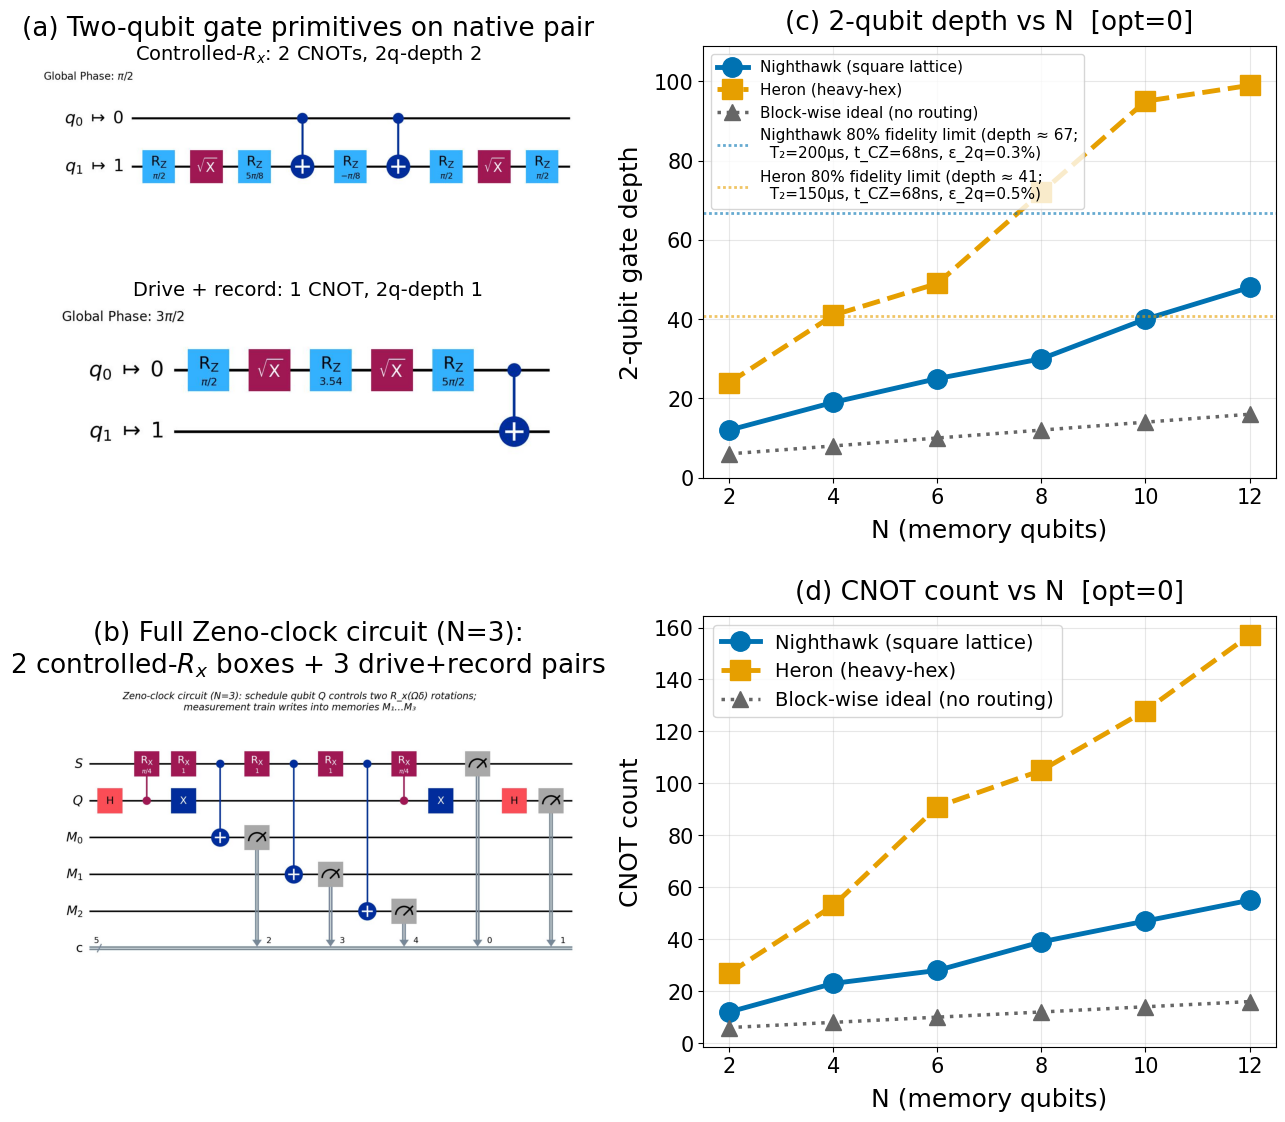

In [ ]:
fig_opt0_xb = make_composite_figure(results_opt0_xb, filename='zeno_feasibility_xbasis_opt0.jpg')


### Observations at opt=0 (Experiment 2)

At $N=8$: Nighthawk needs $39$ CNOTs, 2q-depth $30$. Heron needs $105$ CNOTs, 2q-depth $72$. These are identical to the opt=0 numbers for Experiment 1, as expected — the added Hadamards act on single qubits only and are absorbed into the native single-qubit basis without changing the two-qubit layer structure.

The 80%-fidelity reference lines on panel (c) therefore place Experiment 2 opt=0 in exactly the same position as Experiment 1 opt=0: Nighthawk comfortable below both lines; Heron above its own line for $N \ge 4$. The gate-error budget is the same.

What is **not** captured in these panels is the Experiment 2–specific overhead: the parity signal is damped by $(1 - 2\varepsilon_{\mathrm{ro}})^{N+1}$ by readout error, and the shot budget per data point scales as $1/P(\ket{-}_Q)$. Both are quantified in the intro to this section and in the Caveats.


---

## Part D. Experiment 2 feasibility at optimization_level=2

The second pass for Experiment 2 repeats the sweep at `optimization_level=2`, matching Part B. The physics-preservation argument that justified `opt=2` for Experiment 1 applies here too: SABRE preserves the circuit's unitary (and its DAG, up to swap-equivalence) and so cannot change what the circuit computes. This is the cost estimate that would be submitted to hardware.


In [ ]:
results_opt2_xb = run_sweep_xbasis(opt_level=2)


X-basis sweep at optimization_level = 2

  N |  ideal CNOTs |   NH CNOTs |   HR CNOTs ||  ideal 2q-depth |  NH 2q-depth |  HR 2q-depth
----------------------------------------------------------------------------------------------------
  2 |            6 |          6 |          6 ||               6 |            6 |            6
  4 |            8 |         11 |         14 ||               8 |           11 |           14
  6 |           10 |         14 |         20 ||              10 |           14 |           19
  8 |           12 |         20 |         33 ||              12 |           20 |           32
 10 |           14 |         22 |         41 ||              14 |           22 |           37
 12 |           16 |         31 |         53 ||              16 |           31 |           47


### Composite figure at opt=2 (Experiment 2)


Saved zeno_feasibility_xbasis_opt2.jpg at 300 DPI


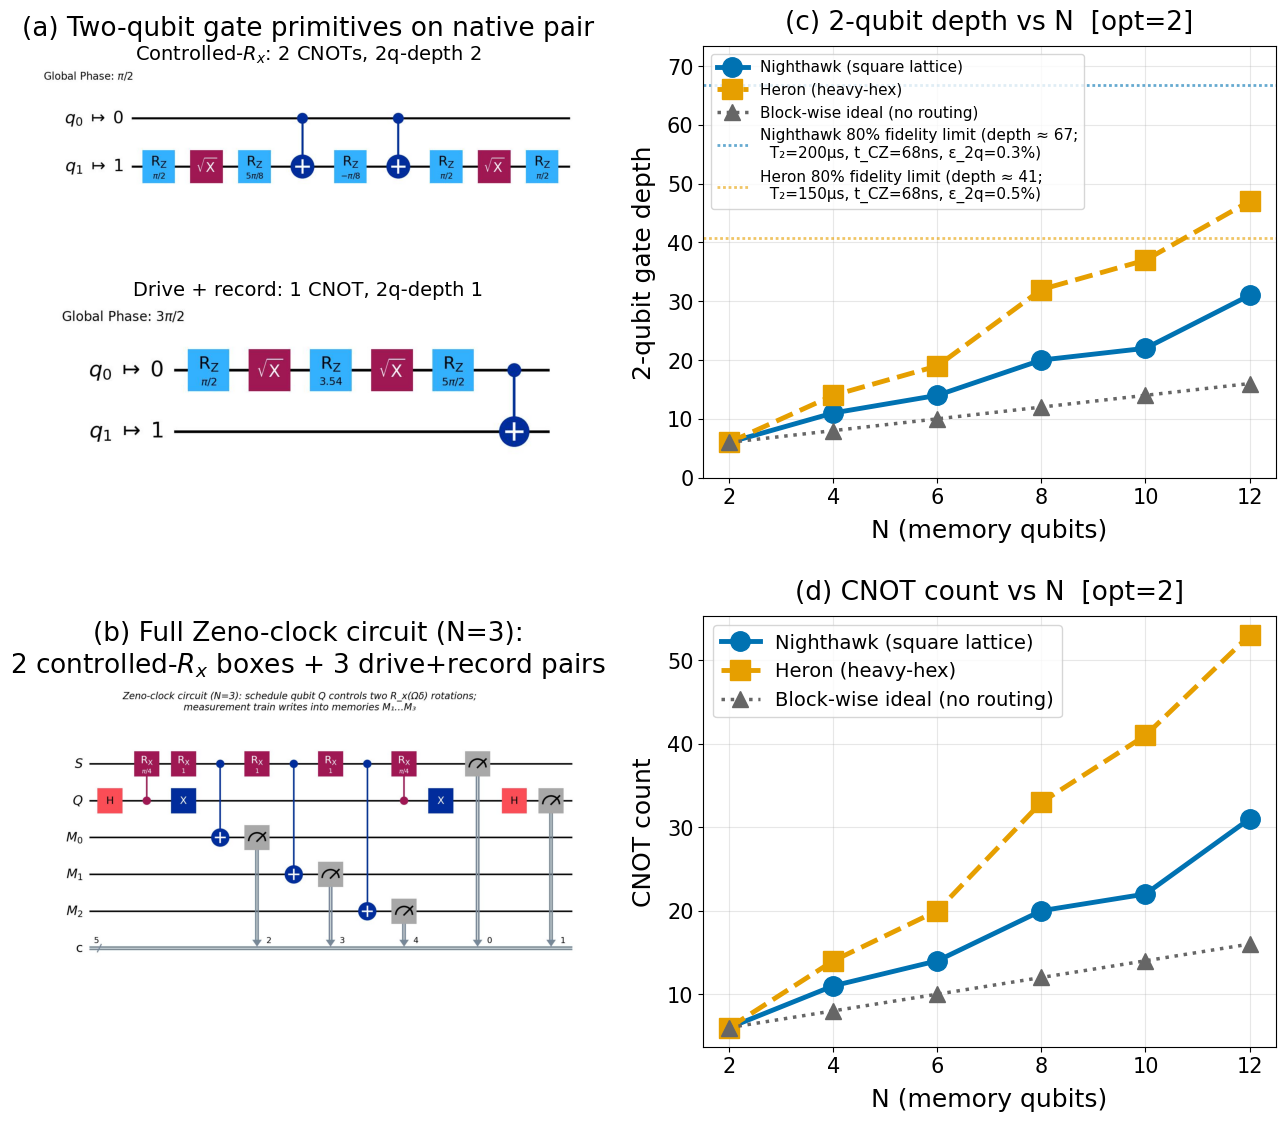

In [ ]:
fig_opt2_xb = make_composite_figure(results_opt2_xb, filename='zeno_feasibility_xbasis_opt2.jpg')


### Observations at opt=2 (Experiment 2)

At $N=8$: Nighthawk needs $20$ CNOTs, 2q-depth $20$. Heron needs $33$ CNOTs, 2q-depth $32$. These match Part B exactly — again because the added Hadamards are single-qubit and leave the two-qubit layer structure untouched.

Both chips sit below their 80%-fidelity reference lines through $N=10$; Heron just touches its line at $N=12$ ($47$ vs. $45$). The gate-error picture for Experiment 2 is identical to Experiment 1.

**Summary at $N=8$ (both experiments, opt=2).**

| metric                           | Expt 1 NH | Expt 1 HR | Expt 2 NH | Expt 2 HR |
|---                               |      ---: |      ---: |      ---: |      ---: |
| CNOTs                            |      $20$ |      $33$ |      $20$ |      $33$ |
| 2q-depth                         |      $20$ |      $32$ |      $20$ |      $32$ |
| qubits read                      |       $2$ |       $2$ |       $9$ |       $9$ |
| readout damping on signal        |      ---  |      ---  |  $(1 - 2\varepsilon_{\mathrm{ro}})^{9}$  |  $(1 - 2\varepsilon_{\mathrm{ro}})^{9}$  |
| required shot budget $\propto$   |      $1$  |      $1$  |  $1/P(\ket{-}_Q)$  |  $1/P(\ket{-}_Q)$  |

**Conclusion.** Experiment 2 inherits Experiment 1's two-qubit depth budget verbatim. Its hardware feasibility depends on two additional quantities that the depth-vs-$N$ panels do not display: readout fidelity on the full $N+1$ qubit register, and the shot budget required to resolve the $\ket{-}_Q$-conditional parity to the desired statistical precision. For a current-generation IBM device with $\varepsilon_{\mathrm{ro}} \lesssim 1.5\%$ and $N=8$, the measured parity is expected to come in near $-0.75$, well separated from the no-signal value of $0$, with $\sim 10^4$ total shots.


## Caveats

Several simplifications affect the interpretation of the numbers above.

**Transpiler randomness.** SABRE uses random tie-breaking. The sweep takes the best of eight seeds for each $(N, \text{topology})$ pair, but a hand-crafted initial layout on a real chip could reduce the CNOT count further.

**Idealized topologies.** `CouplingMap.from_grid(5, 5)` and `CouplingMap.from_heavy_hex(7)` are abstractions. Real chips have defective qubits, non-uniform CNOT fidelities, and daily calibration variation. The Nighthawk-to-Heron ratio here reflects connectivity only.

**What the 80%-fidelity reference lines do not model.** The horizontal lines on panel (c) count accumulated two-qubit gate error only. Three noise channels are not included:

- *$T_1$ decay on $S$.* While $S$ holds population in $\ket{1}_S$, it decays to $\ket{0}_S$ spontaneously with rate $1/T_1$ ($T_1 \sim 100\text{--}200~\mu\text{s}$). For a $15~\mu\text{s}$ circuit, this contributes several percent of extra bias toward $\ket{0}_S$. The $\ket{-}_Q$-branch result is particularly sensitive, because the paper predicts $P_0^{(N,-)}$ to be small; $T_1$ decay drags it up.
- *$T_2$ dephasing on $Q$.* The schedule qubit holds $\ket{+}_Q$ for the entire measurement train — the longest wait in the circuit. Dephasing reduces the fringe visibility $\mathcal{V}$. The paper's Sec. 4 estimates this: at $N=8$, a residual coherence factor of $0.9$ on $Q$ raises $P_0^{(N,-)}$ from the ideal $0.219$ to $0.260$. The baseline run (signature 1 in the paper) measures this factor and can be used to correct the data.
- *$T_2$ dephasing on memories.* Each $M_k$ holds its record from its CNOT until the final readout, so earlier recordings wait longer. The parity readout $\langle \hat{\Sigma}_M \rangle$ is a product over all $N$ memories, so its contrast falls geometrically with per-memory dephasing. Small $N$ is the natural regime for the parity signature.

A quantitative estimate of these channels requires a noise simulation with `qiskit_aer` and a per-qubit noise model, not done here. The 80%-fidelity line is a necessary condition for seeing the signal, not a sufficient one.

**Readout error and crosstalk.** Not modeled above. Readout error is typically 1--2% per qubit, so with ~10 measurements the cumulative bias on specific outcome strings can be 10--20%. The paper's conditional probabilities are ratios of large-count tallies and so more robust than per-string parities. Crosstalk between simultaneous gates on neighboring qubits is sub-percent on current hardware and typically small for a circuit this size.
